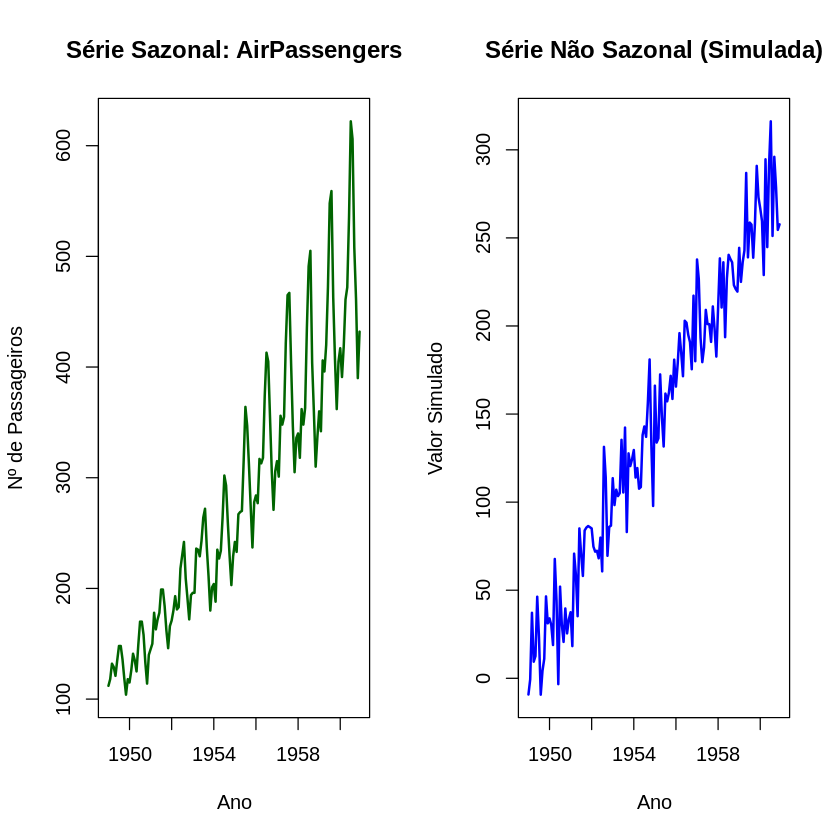

In [ ]:
# Carregar a base AirPassengers (já vem com o R)
data("AirPassengers")

# Criar série não sazonal simulada com tendência e ruído
set.seed(123)
tempo <- 1:length(AirPassengers)
serie_nao_sazonal <- 2 * tempo + rnorm(length(tempo), mean = 0, sd = 20)
ts_nao_sazonal <- ts(serie_nao_sazonal, start = c(1949, 1), frequency = 12)

# Gráficos lado a lado: Sazonal x Não Sazonal
par(mfrow = c(1, 2))

# Série Sazonal: AirPassengers
plot(AirPassengers, main = "Série Sazonal: AirPassengers",
     col = "darkgreen", lwd = 2, ylab = "Nº de Passageiros", xlab = "Ano")

# Série Não Sazonal (Simulada)
plot(ts_nao_sazonal, main = "Série Não Sazonal (Simulada)",
     col = "blue", lwd = 2, ylab = "Valor Simulado", xlab = "Ano")

# Reset layout
par(mfrow = c(1, 1))

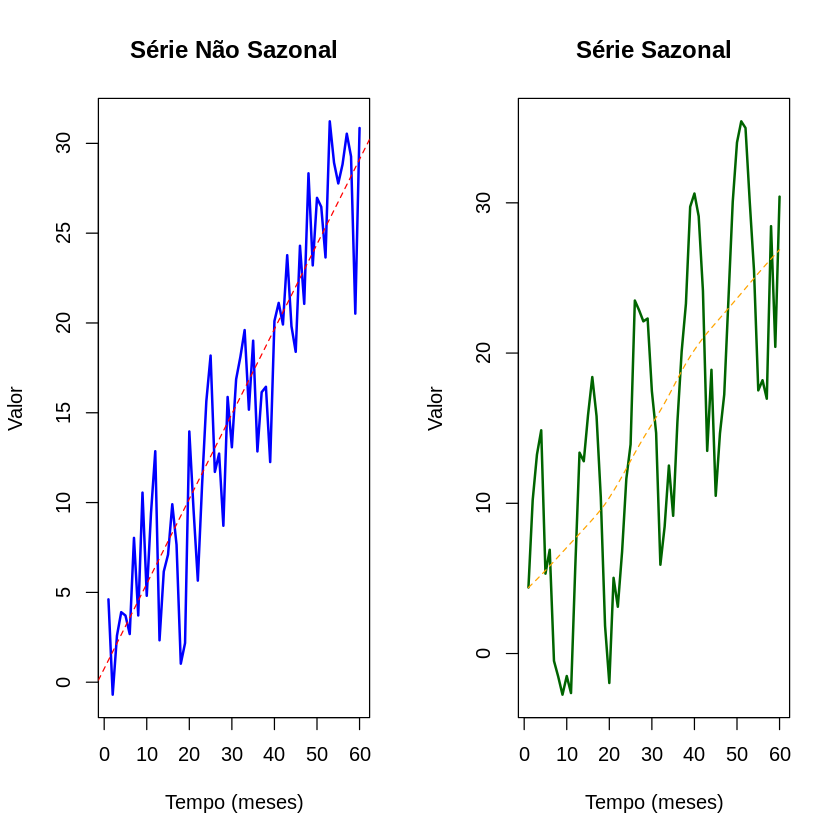

In [ ]:
# Definir semente para reprodutibilidade
set.seed(42)

# Criar sequência de tempo (ex: 5 anos mensais)
tempo <- 1:60  # 60 meses = 5 anos

# Série não sazonal: tendência + ruído
serie_nao_sazonal <- 0.5 * tempo + rnorm(60, mean = 0, sd = 3)

# Série sazonal: tendência + padrão cíclico + ruído
sazonalidade <- 10 * sin(2 * pi * tempo / 12)  # ciclo anual (12 meses)
serie_sazonal <- 0.5 * tempo + sazonalidade + rnorm(60, mean = 0, sd = 3)

# Gráficos lado a lado
par(mfrow = c(1, 2))  # Dois gráficos por linha

# Gráfico da série não sazonal
plot(tempo, serie_nao_sazonal, type = "l", col = "blue", lwd = 2,
     main = "Série Não Sazonal", xlab = "Tempo (meses)", ylab = "Valor")
abline(lm(serie_nao_sazonal ~ tempo), col = "red", lty = 2)

# Gráfico da série sazonal
plot(tempo, serie_sazonal, type = "l", col = "darkgreen", lwd = 2,
     main = "Série Sazonal", xlab = "Tempo (meses)", ylab = "Valor")
lines(lowess(tempo, serie_sazonal), col = "orange", lty = 2)

par(mfrow = c(1,1))  # Reset layout

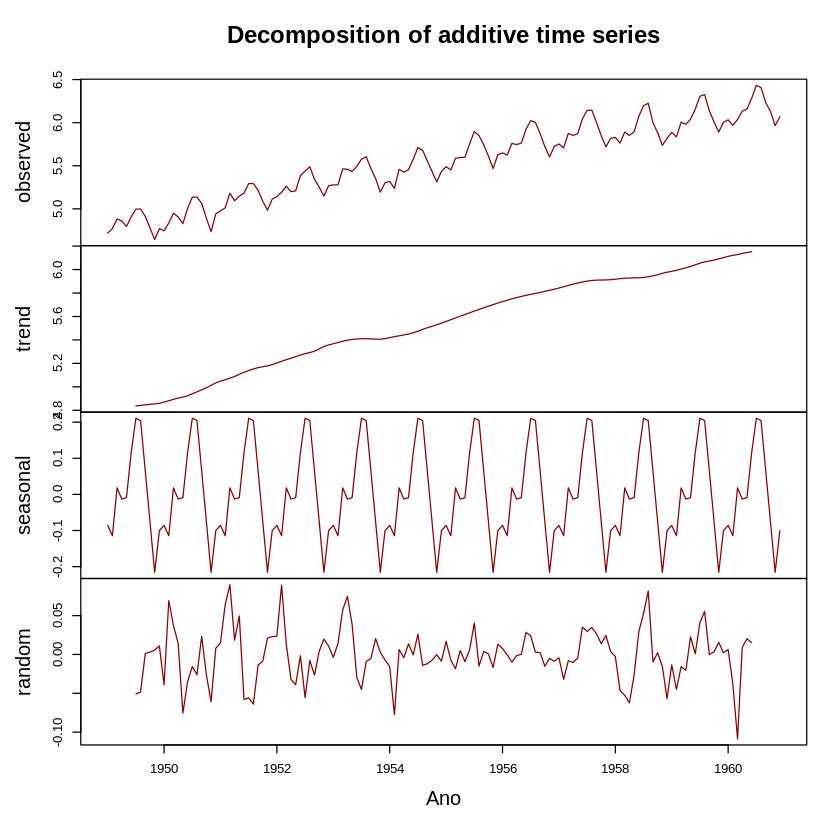

In [ ]:
# Decomposição da série AirPassengers (aditiva)
# Como AirPassengers tem crescimento exponencial, aplicamos log para aproximar da aditividade
log_air <- log(AirPassengers)
decomp <- decompose(log_air, type = "additive")

# Gráfico da decomposição
plot(decomp, col = "darkred", xlab = "Ano")